In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import xarray as xr
import glob
import os
from itertools import combinations

In [2]:
from scipy.cluster import hierarchy

## Creating needed folders

In [3]:
path_plots = '../../plots/DAS_clustering/'

if not os.path.exists(path_plots):
    os.makedirs(path_plots)

In [4]:
res_clustering = '../../data/DAS_clustering/'

if not os.path.exists(res_clustering):
    os.makedirs(res_clustering)

## Clustering parameters

In [5]:
linkagemethod = 'ward'
th = 9000

## Importing data

In [6]:
files = glob.glob('../../../DAS_Caltech/*das_strain_*.h5')
files.sort()

## Processing data

### Without dendrogram

0 ../../../DAS_Caltech/1_das_strain_aug1_sep1_proc_ch_2000_2150.h5
1 ../../../DAS_Caltech/2_das_strain_sep15_dec1_proc_ch_2000_2150.h5
2 ../../../DAS_Caltech/3_das_strain_2025_feb13_may19_proc_ch_2000_2150.h5


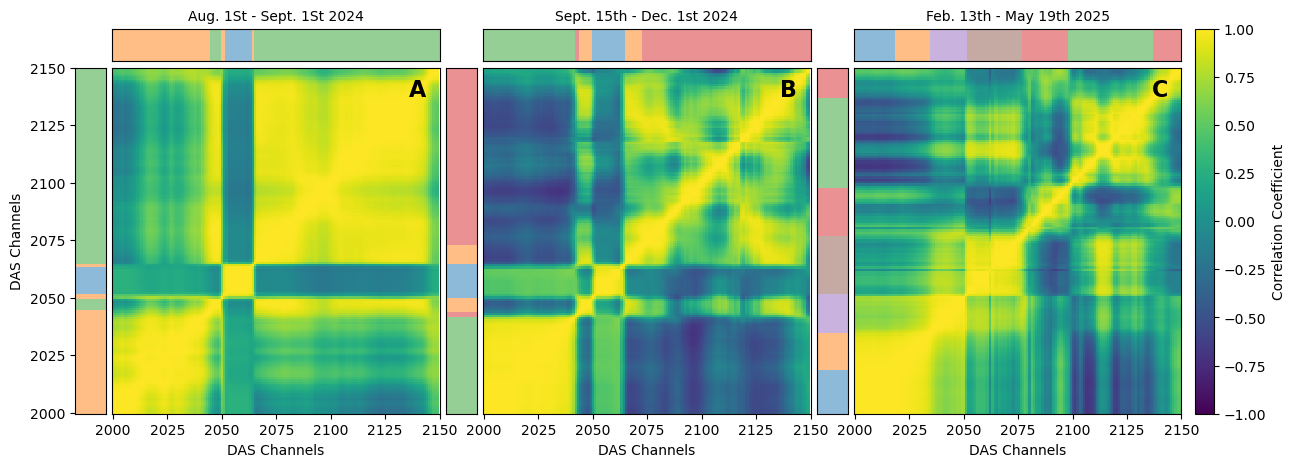

In [7]:
fig = plt.figure(figsize=(17,5))
factor_plot = len(files)
axss = []
letters = ['A', 'B', 'C']
title = ['Aug. 1St - Sept. 1St 2024','Sept. 15th - Dec. 1st 2024','Feb. 13th - May 19th 2025']
for f, file in enumerate(files):
    print(f, file)
    das_data = xr.open_dataset(file)
    das_data['strain'] = das_data.strain - das_data.strain.mean(dim='time')
    corrcoef_matrix_das = np.corrcoef(das_data.strain.values)
    H = hierarchy.linkage(das_data.strain.values, method=linkagemethod)
    label = hierarchy.fcluster(H, th, criterion='distance')
    df = pd.DataFrame({'channel': das_data.channel.values, 'label': label})
    df.to_csv(res_clustering+'/clustering_DAS_labels_'+file.split('/')[-1].split('.')[0]+'.csv', index=False)

    ax = plt.subplot2grid((10,10*factor_plot), (0,1+f*10), rowspan=1, colspan=9, )
    axb = plt.subplot2grid((10,10*factor_plot), (1,0+f*10), rowspan=9, colspan=1)
    for i in range(len(label)):
        ax.fill_betweenx([0,1], i-.5, i+.5, facecolor='C'+str(label[i]-1), alpha=0.5)
        axb.fill_between([0,1], i-.5, i+.5, facecolor='C'+str(label[i]-1), alpha=0.5)
    if f > 0 :
        axb.set_yticks([])
    #else : 
    #    axb.set_yticks([])
    ax.set_title(title[f], fontsize=10) 
    ax.set_xlim(-0.5, len(label)-.5)
    ax.set_ylim(0,1), ax.set_yticks([]), ax.set_xticks([])
    axb.set_ylim(0-.5, len(label)-.5)
    axb.set_xlim(0,1)
    axb.set_xticks([])
    if f == 0 :
        axb.set_ylabel('DAS Channels')
        axb.set_yticks(np.arange(0, len(label)+1, 25),
                       np.arange(2000, 2000+len(label)+1, 25, dtype=int))

    ax2 = plt.subplot2grid((10,10*factor_plot), (1,1+f*10), rowspan=9, colspan=9)
    ax2.imshow(corrcoef_matrix_das, cmap='viridis', aspect='auto', interpolation='none', origin='lower', vmin=-1, vmax=1)
    ax2.set_yticks([])
    ax2.set_xlabel('DAS Channels')
    ax2.set_xticks(np.arange(0, corrcoef_matrix_das.shape[0]+1, 25), 
                   np.arange(2000, 2000+corrcoef_matrix_das.shape[0]+1, 25, dtype=int))
    axss += [ax, axb, ax2]
    ax2.text(140,140, letters[f], fontsize=16, fontweight='bold', color='k', ha='center', va='center')
fig.colorbar(ax2.images[0], ax=axss, location='right', label='Correlation Coefficient', pad=0.01)
plt.savefig(path_plots+'/clustering_DAS.png', dpi=300, bbox_inches='tight')
plt.show()

### With dendrogram

0 ../../../DAS_Caltech/1_das_strain_aug1_sep1_proc_ch_2000_2150.h5
1 ../../../DAS_Caltech/2_das_strain_sep15_dec1_proc_ch_2000_2150.h5


2 ../../../DAS_Caltech/3_das_strain_2025_feb13_may19_proc_ch_2000_2150.h5


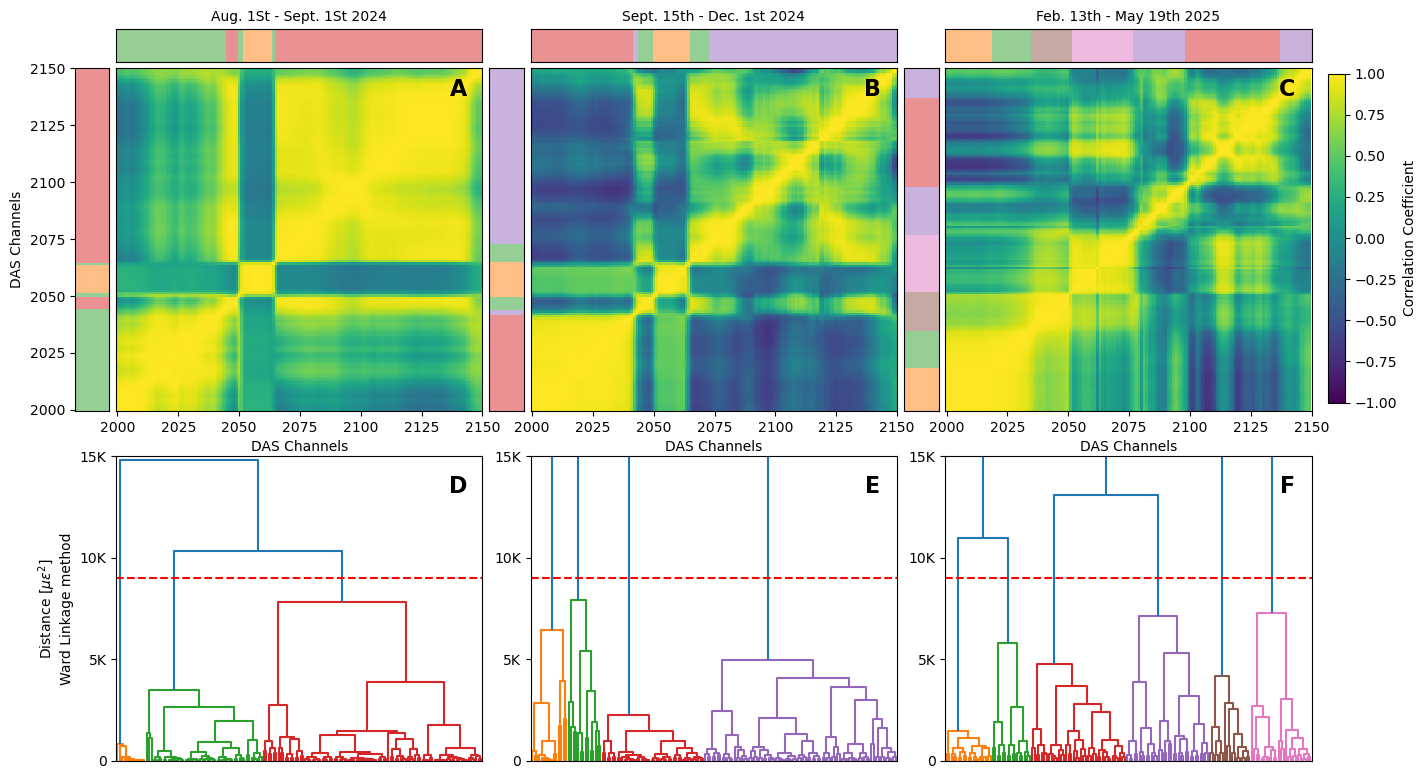

In [8]:
fig = plt.figure(figsize=(19,10))
factor_plot = len(files)
axss = []
letters = ['A', 'B', 'C']
letters_line2 = ["D", "E", "F"]
title = ['Aug. 1St - Sept. 1St 2024','Sept. 15th - Dec. 1st 2024','Feb. 13th - May 19th 2025']
for f, file in enumerate(files):
    print(f, file)
    das_data = xr.open_dataset(file)
    das_data['strain'] = das_data.strain - das_data.strain.mean(dim='time')
    corrcoef_matrix_das = np.corrcoef(das_data.strain.values)
    H = hierarchy.linkage(das_data.strain.values, method=linkagemethod)
    label = hierarchy.fcluster(H, th, criterion='distance')
    df = pd.DataFrame({'channel': das_data.channel.values, 'label': label})
    df.to_csv(res_clustering+'/clustering_DAS_labels_'+file.split('/')[-1].split('.')[0]+'.csv', index=False)

    ax = plt.subplot2grid((20,10*factor_plot), (0,1+f*10), rowspan=1, colspan=9, )
    axb = plt.subplot2grid((20,10*factor_plot), (1,0+f*10), rowspan=9, colspan=1)

    for i in range(len(label)):
        ax.fill_betweenx([0,1], i-.5, i+.5, facecolor='C'+str(label[i]), alpha=0.5)
        axb.fill_between([0,1], i-.5, i+.5, facecolor='C'+str(label[i]), alpha=0.5)
    if f > 0 :
        axb.set_yticks([])
    #else : 
    #    axb.set_yticks([])
    ax.set_title(title[f], fontsize=10) 
    ax.set_xlim(-0.5, len(label)-.5)
    ax.set_ylim(0,1), ax.set_yticks([]), ax.set_xticks([])
    axb.set_ylim(0-.5, len(label)-.5)
    axb.set_xlim(0,1)
    axb.set_xticks([])
    axDendro = plt.subplot2grid((20,10*factor_plot), (11,1+f*10), rowspan=8, colspan=9)
    if f == 0 :
        axb.set_ylabel('DAS Channels')
        axb.set_yticks(np.arange(0, len(label)+1, 25),
                       np.arange(2000, 2000+len(label)+1, 25, dtype=int))
        axDendro.set_ylabel('Distance [$\mu \epsilon^2$]\nWard Linkage method')
    
    hierarchy.dendrogram(H, ax=axDendro, color_threshold=th, p=30)
    axDendro.set_yticks(np.arange(0, 15001, 5000), ['0', '5K', '10K', '15K'])
    axDendro.set_xticks([],[])
    axDendro.set_ylim(0,15000)
    axDendro.axhline(th, color='r', ls='--')
    ax2 = plt.subplot2grid((20,10*factor_plot), (1,1+f*10), rowspan=9, colspan=9)
    ax2.imshow(corrcoef_matrix_das, cmap='viridis', aspect='auto', interpolation='none', origin='lower', vmin=-1, vmax=1)
    ax2.set_yticks([])
    ax2.set_xlabel('DAS Channels')
    ax2.set_xticks(np.arange(0, corrcoef_matrix_das.shape[0]+1, 25), 
                   np.arange(2000, 2000+corrcoef_matrix_das.shape[0]+1, 25, dtype=int))
    axss += [ax, axb, ax2, axDendro]
    ax2.text(140,140, letters[f], fontsize=16, fontweight='bold', color='k', ha='center', va='center')
    axDendro.text(1400, 13500, letters_line2[f], fontsize=16, fontweight='bold', color='k', ha='center', va='center')
fig.colorbar(ax2.images[0], ax=axss, location='right', label='Correlation Coefficient', pad=0.01, shrink=0.45, anchor=(0.01, 0.89))
plt.savefig(path_plots+'/dendro_clustering_DAS.png', dpi=300, bbox_inches='tight')
plt.show()